# SeismicArray Demo

This notebook demonstrates how to use the SeismicArray class for array-derived rotation (ADR) computation.


## Notebook Overview
This notebook retrieves ADR-related waveform data for configured events and prepares it for downstream ROMY analysis.

**Main workflow**
- Read event timing/configuration information.
- Request and load ADR waveform data for selected windows.
- Apply basic preprocessing and quality checks.
- Store prepared data in event-specific locations for later processing.

In [1]:
import yaml

from obspy import UTCDateTime
from sixdegrees.seismicarray import seismicarray


In [17]:
# set event date
# event date = '20190514' # no data

# event_date = '20230908'
# event_date = '20230912' # bad Z with jump
# event_date = '20231202'  # no GELB, ALFT
# event_date = '20231203' # no data

# event_date = '20240314' # no ALFT, BIB
# event_date = '20240322' # no ALFT, BIB
# event_date = '20240323' # no ALFT (BIB, TON)
# event_date = '20240414' # no ALFT
# event_date = '20240422' # no ALFT (BIB)
# event_date = '20240815' # no ALFT
# event_date = '20241023' # no ALFT (BIB)
# event_date = '20240915' # no ALFT (BIB)

# event_date = '20250602' # no ALFT, GELB
# event_date = '20250513' # no ALFT GELB
# event_date = '20251206' # no ALFT, GELB
# event_date = '20251212' # no ALFT, GELB
# event_date = '20251227' # no ALFT, GELB

event_date = '20260107' # no ALFT, GELB
# event_date = '20260420' # no ALFT, GELB

## 1. Create Configuration File

First, let's create a YAML configuration file for our seismic array.


In [18]:
config = {
    # specify fdsn client
    'fdsn_client': ['LMU', 'BGR'],

    # specify stations
    'stations': [
        "GR.FUR",
        # "BW.FFB1",
        # "BW.FFB2",
        # "BW.FFB3",
        "BW.TON",
        "BW.BIB",
        "BW.GRMB",
        # "BW.GELB",
        # "BW.ALFT"
    ],
    
    # specify reference station
    'reference_station': 'GR.FUR',
    
    # specify channel prefix
    'channel_prefix': 'B',  # Broadband channels
    
    # specify response output
    'response_output': 'VEL',  # Output velocity (VEL, DISP, ACC)
    
    # specify ADR parameters
    'vp': 5800,  # P-wave velocity in m/s
    'vs': 3300,  # S-wave velocity in m/s
    'sigmau': 1e-9  # Uncertainty in displacement
}

# Save configuration to file
config_filename = './config_array_romy.yml'
with open(config_filename, 'w') as f:
    yaml.dump(config, f)


In [19]:
# extract time period from other config file
date = event_date.replace("-", "")
config_event = yaml.load(open(f'./events/event_{date}/config_romy_{date}.yml'), Loader=yaml.FullLoader)
tbeg = UTCDateTime(config_event['tbeg'])
tend = UTCDateTime(config_event['tend'])


## 2. Initialize SeismicArray

Now we can create a SeismicArray instance using our configuration.


In [20]:
# setup array instance
array = seismicarray(config_filename)

# Show array configuration
array.show_array_info()


├── stations: ['GR.FUR', 'BW.TON', 'BW.BIB', 'BW.GRMB']
├── reference_station: GR.FUR
├── channel_prefix: B
├── channel_prefixes: ['B']
├── channel_prefix_mapping
        │   ├── GR.FUR: B
        │   ├── BW.TON: B
        │   ├── BW.BIB: B
        │   └── BW.GRMB: B
├── response_output: VEL
├── fdsn_clients: ['LMU', 'BGR']
├── client_mapping
        │   ├── GR.FUR: LMU
        │   ├── BW.TON: LMU
        │   ├── BW.BIB: LMU
        │   └── BW.GRMB: LMU
├── adr_parameters
        │   ├── vp: 5800.0
        │   ├── vs: 3300.0
        │   └── sigmau: 1e-09
├── station_coordinates
├── station_distances
└── failed_stations: []


## 3. Get Station Inventories

Fetch station metadata and compute inter-station distances.


In [21]:
# Get inventories
array.request_inventories(tbeg, tend)

# Compute distances
array.compute_station_distances()


In [22]:
array.show_array_info()

├── stations: ['GR.FUR', 'BW.TON', 'BW.BIB', 'BW.GRMB']
├── reference_station: GR.FUR
├── channel_prefix: B
├── channel_prefixes: ['B']
├── channel_prefix_mapping
        │   ├── GR.FUR: B
        │   ├── BW.TON: B
        │   ├── BW.BIB: B
        │   └── BW.GRMB: B
├── response_output: VEL
├── fdsn_clients: ['LMU', 'BGR']
├── client_mapping
        │   ├── GR.FUR: BGR
        │   ├── BW.TON: LMU
        │   ├── BW.BIB: LMU
        │   └── BW.GRMB: LMU
├── adr_parameters
        │   ├── vp: 5800.0
        │   ├── vs: 3300.0
        │   └── sigmau: 1e-09
├── station_coordinates
        │   ├── GR.FUR
                │   │   ├── latitude: 48.1639
                │   │   ├── longitude: 11.2768
                │   │   └── elevation: 565.0
        │   ├── BW.TON
                │   │   ├── latitude: 48.173897
                │   │   ├── longitude: 11.288809
                │   │   └── elevation: 564.0
        │   ├── BW.BIB
                │   │   ├── latitude: 48.1522
                │   

## 4. Get and Process Waveforms


processing to be applied:  
 response: True 
 rotate: to ZNE 
 detrend: True 
 taper: True 
 filter: True
--------------------
requesting waveforms for station GR.FUR using BGR (prefix: B)
 -> successfully obtained waveforms for GR.FUR using BGR (prefix: B)
--------------------
requesting waveforms for station BW.TON using LMU (prefix: B)
 -> successfully obtained waveforms for BW.TON using LMU (prefix: B)
--------------------
requesting waveforms for station BW.BIB using LMU (prefix: B)
 -> successfully obtained waveforms for BW.BIB using LMU (prefix: B)
--------------------
requesting waveforms for station BW.GRMB using LMU (prefix: B)
 -> failed with mapped prefix B: No data available for request.
HTTP Status code: 204
Detailed response of server:


--------------------
requesting waveforms for station BW.GRMB using BGR (prefix: B)
 -> failed with mapped prefix B: No data available for request.
HTTP Status code: 204
Detailed response of server:


 -> dropping station BW.GRMB: Failed

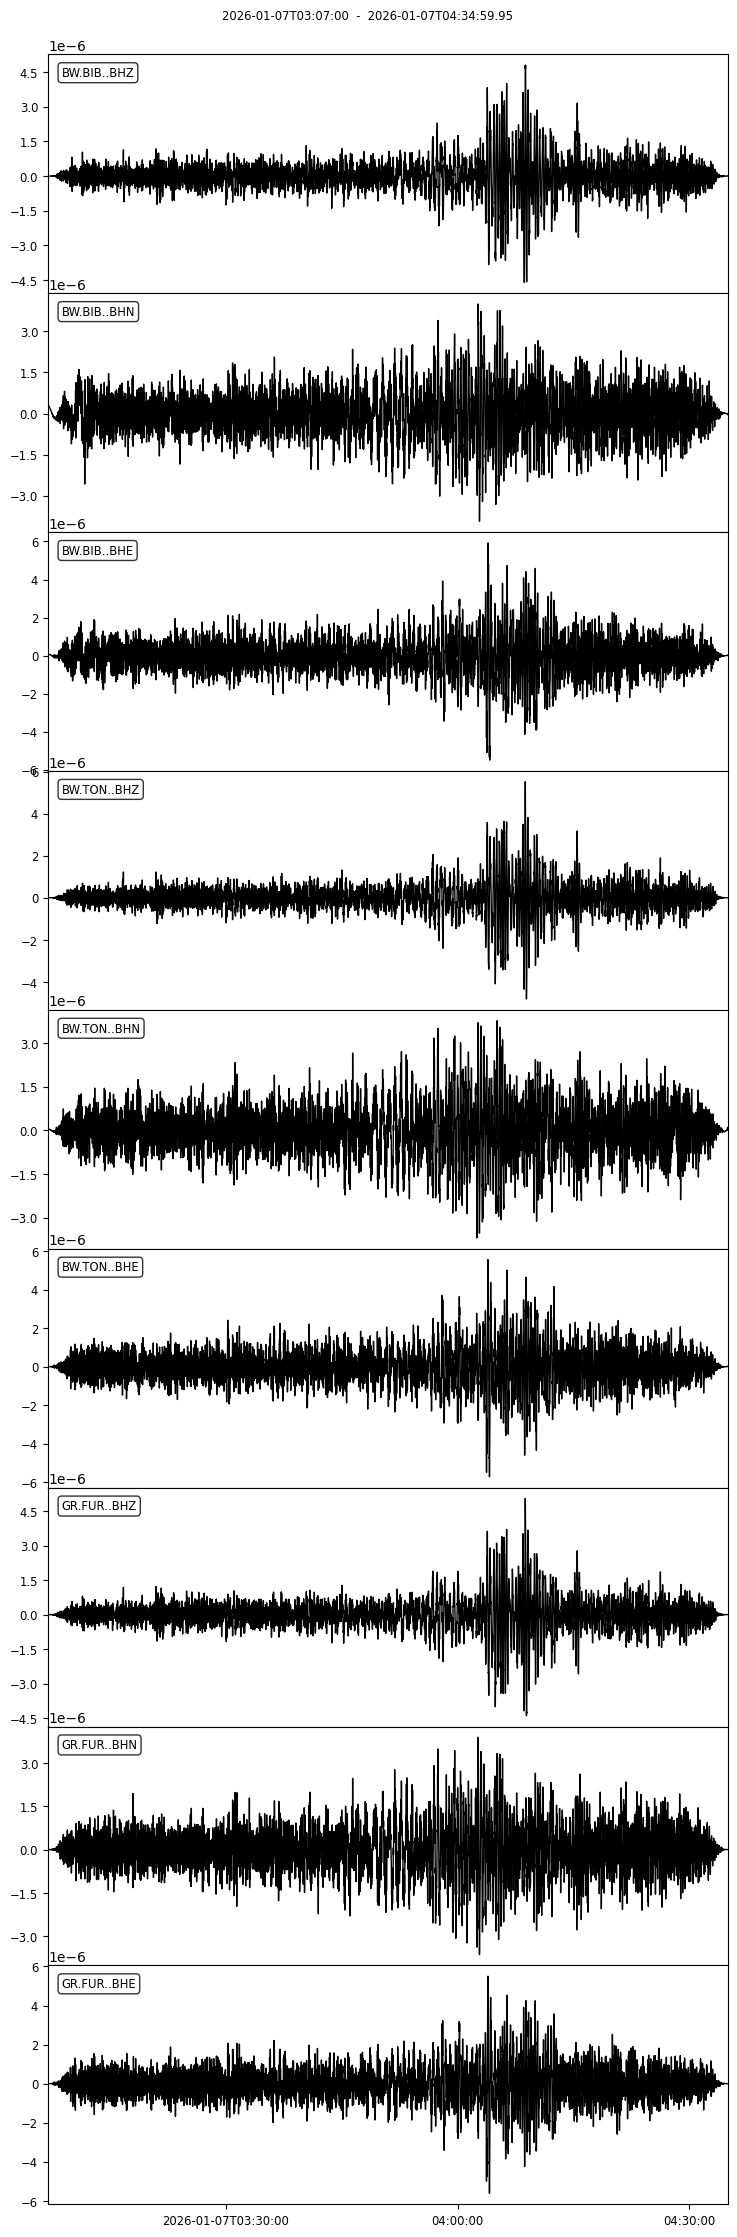

9 Trace(s) in Stream:
GR.FUR..BHE | 2026-01-07T03:07:00.000000Z - 2026-01-07T04:34:59.950000Z | 20.0 Hz, 105600 samples
GR.FUR..BHN | 2026-01-07T03:07:00.000000Z - 2026-01-07T04:34:59.950000Z | 20.0 Hz, 105600 samples
GR.FUR..BHZ | 2026-01-07T03:07:00.000000Z - 2026-01-07T04:34:59.950000Z | 20.0 Hz, 105600 samples
BW.BIB..BHE | 2026-01-07T03:07:00.000000Z - 2026-01-07T04:34:59.950000Z | 20.0 Hz, 105600 samples
BW.BIB..BHN | 2026-01-07T03:07:00.000000Z - 2026-01-07T04:34:59.950000Z | 20.0 Hz, 105600 samples
BW.BIB..BHZ | 2026-01-07T03:07:00.000000Z - 2026-01-07T04:34:59.950000Z | 20.0 Hz, 105600 samples
BW.TON..BHE | 2026-01-07T03:07:00.000000Z - 2026-01-07T04:34:59.950000Z | 20.0 Hz, 105600 samples
BW.TON..BHN | 2026-01-07T03:07:00.000000Z - 2026-01-07T04:34:59.950000Z | 20.0 Hz, 105600 samples
BW.TON..BHZ | 2026-01-07T03:07:00.000000Z - 2026-01-07T04:34:59.950000Z | 20.0 Hz, 105600 samples

In [23]:
# Get waveforms with preprocessing
stream = array.request_waveforms(
    tbeg,
    tend,
    remove_response=True,
    detrend=True,
    taper=True,
    filter_params={'type': 'bandpass', 'freqmin': 0.008, 'freqmax': 0.5, 'corners': 4, 'zerophase': True},
    verbose=True
)

# Plot the waveforms
stream.plot(equal_scale=False);

stream

In [24]:
array.show_array_info()

├── stations: ['GR.FUR', 'BW.TON', 'BW.BIB']
├── reference_station: GR.FUR
├── channel_prefix: B
├── channel_prefixes: ['B']
├── channel_prefix_mapping
        │   ├── GR.FUR: B
        │   ├── BW.TON: B
        │   └── BW.BIB: B
├── response_output: VEL
├── fdsn_clients: ['LMU', 'BGR']
├── client_mapping
        │   ├── GR.FUR: BGR
        │   ├── BW.TON: LMU
        │   └── BW.BIB: LMU
├── adr_parameters
        │   ├── vp: 5800.0
        │   ├── vs: 3300.0
        │   └── sigmau: 1e-09
├── station_coordinates
        │   ├── GR.FUR
                │   │   ├── latitude: 48.1639
                │   │   ├── longitude: 11.2768
                │   │   └── elevation: 565.0
        │   ├── BW.TON
                │   │   ├── latitude: 48.173897
                │   │   ├── longitude: 11.288809
                │   │   └── elevation: 564.0
        │   └── BW.BIB
                │       ├── latitude: 48.1522
                │       ├── longitude: 11.2473
                │       └── elevation: 5

Ignoring fixed y limits to fulfill fixed data aspect with adjustable data limits.


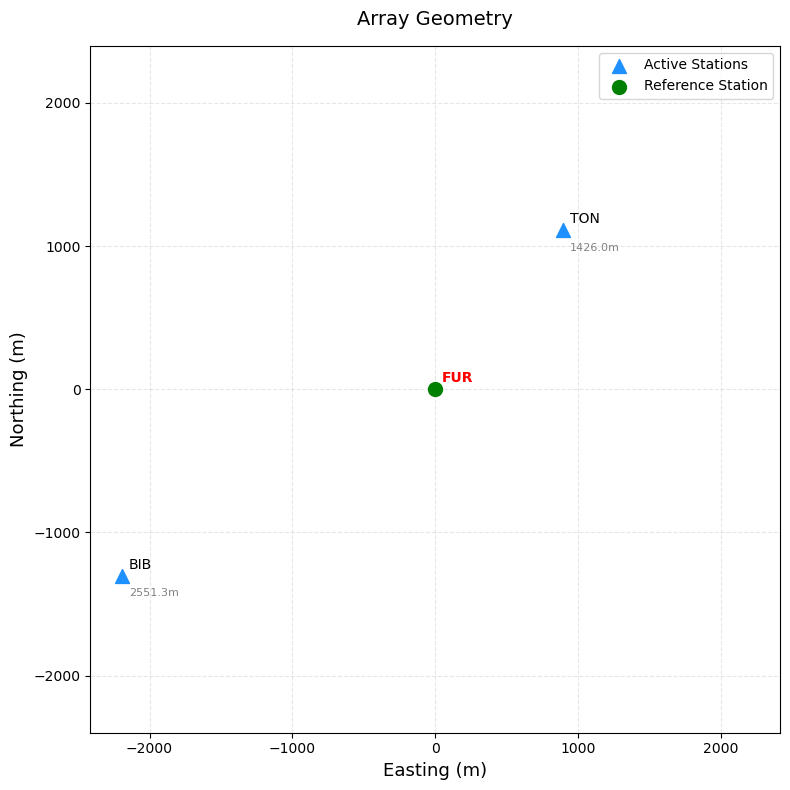

In [25]:
array.plot_array_geometry(
    show_dropped=True,
    # save_path='./figures/array_geometry.png'
    )

## 5. Compute Array-Derived Rotation



Preparing data for ADR computation:
 -> using GR.FUR as reference station
 -> added GR.FUR components to arrays
 -> added BW.TON components to arrays
 -> added BW.BIB components to arrays

Preparing station coordinates:
 -> GR.FUR coordinates [m]: E=0.0, N=0.0, Z=0.0
 -> BW.TON coordinates [m]: E=893.3, N=1111.6, Z=-1.0
 -> BW.BIB coordinates [m]: E=-2194.7, N=-1301.0, Z=34.0

Computing array-derived rotation:
 -> using 3 stations


/home/andbro/anaconda3/envs/sixdegrees/lib/python3.10/site-packages/obspy/signal/array_analysis.py:264: UserWarning: For a 3-station array the problem is even-determined
  warnings.warn(msg)
/home/andbro/anaconda3/envs/sixdegrees/lib/python3.10/site-packages/obspy/signal/array_analysis.py:331: UserWarning: Condition number is 121.77206493010127
  warnings.warn(msg)


 -> ADR computation completed
 -> created rotation trace: GR.FUR..BJZ
 -> created rotation trace: GR.FUR..BJN
 -> created rotation trace: GR.FUR..BJE


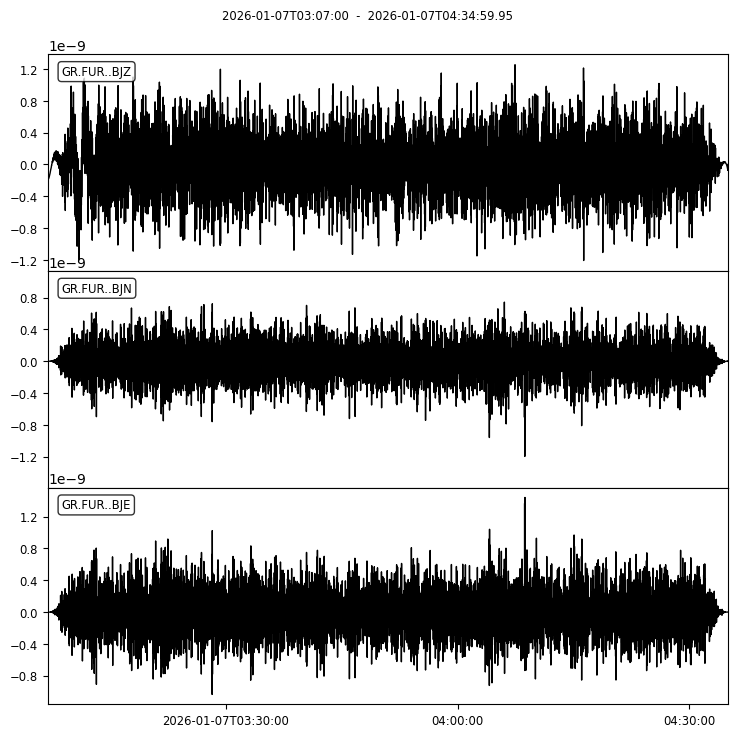

In [26]:
# Compute ADR
rot_stream = array.compute_adr(output=True, verbose=True)

# Plot rotation rates
rot_stream.plot();


In [27]:
# for tr in array.rot_stream:
#     tr.stats.network = "XX"
#     tr.stats.station = "ADR"

# for tr in array.stream:
#     if tr.stats.station == config['reference_station'].split('.')[1]:
#         tr.stats.network = "XX"
#         tr.stats.station = "ADR"


## 6. Save 6 Degrees of Freedom Data


The 6-DoF stream can be saved as a mseed file or to a SDS file system.

In [28]:
# Save as MiniSEED file
array.save_6dof_data(
    output_format='file', # 'file' or 'sds'
    output_path=f'./events/event_{date}/',
    output_file=f'adr_{date}.mseed'
)


/home/andbro/anaconda3/envs/sixdegrees/lib/python3.10/site-packages/obspy/io/mseed/core.py:773: UserWarning: The encoding specified in trace.stats.mseed.encoding does not match the dtype of the data.
A suitable encoding will be chosen.
  warnings.warn(msg, UserWarning)


Also, a configuration file can be stored, to read the data as a sixdegrees object for analyses.

In [29]:
array.config['path_to_data_out'] = "./output/"
array.config['path_to_figures'] = f"./events/event_{date}/figures/"
array.config['path_to_mseed_file'] = f"./events/event_{date}/adr_{date}.mseed"
# array.config['project'] = f"event_{date}"

array.config['station_lat'] = 48.162941
array.config['station_lon'] = 11.275476

array.config['seed'] = "GR.FUR.."
array.config['rot_seed'] = ["GR.FUR..BJZ", "GR.FUR..BJN", "GR.FUR..BJE"]
array.config['tra_seed'] = ["GR.FUR..BHZ", "GR.FUR..BHN", "GR.FUR..BHE"]


In [30]:
array.save_config_for_sixdegrees(
    output_path=f'./events/event_{date}/',
    output_file=f'config_adr_{date}.yml',
)

Configuration saved to events/event_20260107/config_adr_20260107.yml


In [31]:
# modify config
conf = yaml.load(open(f'./events/event_{date}/config_adr_{date}.yml'), Loader=yaml.FullLoader)

# add number of stations to config
conf['stations'] = array.stations

# write modified config
with open(f'./events/event_{date}/config_adr_{date}.yml', 'w') as f:
    yaml.dump(conf, f)
